# Grad-CAM++ for MMBCNet Sonography Model (3-class breast ultrasound)

This notebook loads an **already-trained** MMBCNet sonography branch model
(`RadImageNet DenseNet121 → CBAM → GAP/GMP → Dense head`) from Google Drive
and generates **Grad-CAM++** explanations. It does **not** retrain, fine-tune,
or modify the model or its weights in any way.

Classes: `0 = Benign`, `1 = Malignant`, `2 = Normal`

The only cells you should normally need to edit are marked **`# >>> EDIT`**:
- `MODEL_PATH`
- `TEST_DIR`
- `TARGET_LAYER_NAME` (only if automatic detection fails)


## 1. Install / Import Dependencies

In [ ]:
# TensorFlow/Keras is preinstalled on Colab. We only pull in the extras we need.
!pip install -q opencv-python-headless scikit-image

import os
import io
import glob
import random
import textwrap
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, backend as K

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.20.0
Keras: 3.13.2
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 3. Configuration

In [ ]:
# >>> EDIT: point this at your trained .keras file
MODEL_PATH = "/content/drive/MyDrive/Busi_Model/Frozen92.16.keras"  # >>> EDIT

# >>> EDIT (optional): directory of held-out test images, arranged either as
#     TEST_DIR/<ClassName>/*.png  (labeled)  or a flat folder of images (unlabeled)
TEST_DIR = "/content/drive/MyDrive/..."  # >>> EDIT

# Class ordering is fixed by the trained model — do not change.
CLASS_NAMES = ["Benign", "Malignant", "Normal"]  # 0, 1, 2
NUM_CLASSES = len(CLASS_NAMES)

IMG_SIZE = 300  # 300 x 300 x 3 RGB input, matches training pipeline

# Grad-CAM++ target layer. Leave as None to auto-detect the post-CBAM,
# pre-GAP/GMP 4-D feature map. Only set manually if auto-detection fails.
TARGET_LAYER_NAME = None  # >>> EDIT (only if automatic detection fails)

# Class to explain. None = explain the model's predicted class.
class_index = None  # 0=Benign, 1=Malignant, 2=Normal, or None

OUTPUT_DIR = "/content/drive/MyDrive/Busi_Model/GradCAM_PP"
# Visualization layout: "duo" = Original | Activation-Heatmap-overlay
#                                (dark styled, matches mammography-model look)
#                        "triptych" = Original | Heatmap | Overlay (3 panels)
VISUALIZATION_STYLE = "duo"  # >>> EDIT: "duo" or "triptych"

# Heatmap cleanup -- controls how "focused" vs "washed out" the overlay looks
HEATMAP_THRESHOLD_PERCENTILE = 45
HEATMAP_GAMMA = 1.5
HEATMAP_BLUR_KERNEL = 15
OVERLAY_MAX_ALPHA = 0.65

#HEATMAP_THRESHOLD_PERCENTILE = 10  # >>> EDIT: suppress activation below this percentile (0 = off)
#HEATMAP_GAMMA = 1.5                # >>> EDIT: >1 sharpens the peak, fades the tail faster
#HEATMAP_BLUR_KERNEL = 15           # >>> EDIT: odd int, smooths the surviving blob (0 = off)
#OVERLAY_MAX_ALPHA = 0.65           # >>> EDIT: blend strength AT peak activation only

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Output directory ready:", OUTPUT_DIR)


Output directory ready: /content/drive/MyDrive/Busi_Model/GradCAM_PP


## 4. Custom Objects

Registers everything the saved model may need to deserialize: the `mish`
activation, the focal-loss factory used during training, and the CBAM
building blocks (only needed if CBAM was saved as custom Lambda/layer
objects rather than plain Keras layers). We load the model with
`compile=False`, so the loss function does not need to match training
exactly — it only needs to exist so Keras doesn't error while parsing the
model config if a loss reference was serialized inside it.


In [ ]:
# --- Mish activation -------------------------------------------------------
# NOTE: we don't use @keras.saving.register_keras_serializable here -- its
# import path varies across Keras versions/environments. Instead we rely on
# the CUSTOM_OBJECTS dict passed into load_model(). Keras looks functions up
# by the EXACT name string that was baked into the saved model's config at
# training time (visible in load errors as e.g. "Could not locate function
# 'Custom>mish'"). We register both the plain name and that exact
# "Custom>...": prefixed name so the lookup succeeds regardless of which
# form the saved file used.
def mish(x):
    return x * tf.math.tanh(tf.math.softplus(x))

# --- Focal loss (factory + a plain callable variant, for compatibility) ----
def focal_loss(y_true, y_pred, gamma=2.0, alpha=0.25):
    y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())
    cross_entropy = -y_true * tf.math.log(y_pred)
    weight = alpha * tf.math.pow(1.0 - y_pred, gamma)
    return tf.reduce_sum(weight * cross_entropy, axis=-1)

def focal_loss_factory(gamma=2.0, alpha=0.25):
    def _loss(y_true, y_pred):
        return focal_loss(y_true, y_pred, gamma=gamma, alpha=alpha)
    return _loss

# --- CBAM building blocks (only used if the saved model references them
#     as named custom objects rather than plain built-in Keras layers) ------
def cbam_block(input_tensor, ratio=8):
    channel = input_tensor.shape[-1]
    shared_1 = layers.Dense(channel // ratio, activation='relu',
                             kernel_initializer='he_normal')
    shared_2 = layers.Dense(channel, kernel_initializer='he_normal')

    avg_pool = layers.Reshape((1, 1, channel))(
        layers.GlobalAveragePooling2D()(input_tensor))
    max_pool = layers.Reshape((1, 1, channel))(
        layers.GlobalMaxPooling2D()(input_tensor))

    channel_att = layers.Activation('sigmoid')(
        layers.Add()([shared_2(shared_1(avg_pool)),
                       shared_2(shared_1(max_pool))]))

    refined = layers.Multiply()([input_tensor, channel_att])

    avg_sp = keras.ops.mean(refined, axis=-1, keepdims=True)
    max_sp = keras.ops.max(refined, axis=-1, keepdims=True)

    sp_att = layers.Conv2D(
        1, 7, padding='same', activation='sigmoid',
        kernel_initializer='he_normal', use_bias=False
    )(layers.Concatenate(axis=-1)([avg_sp, max_sp]))

    return layers.Multiply()([refined, sp_att])

# Collected registry passed to load_model(). Keras raises a TypeError naming
# the exact missing string (e.g. "Could not locate function 'Custom>xyz'")
# when something here is still missing -- add that exact string as a new
# key mapped to the right Python object and re-run this cell + the load cell.
CUSTOM_OBJECTS = {
    "mish": mish,
    "Custom>mish": mish,
    "focal_loss": focal_loss,
    "Custom>focal_loss": focal_loss,
    "focal_loss_factory": focal_loss_factory,
    "Custom>focal_loss_factory": focal_loss_factory,
    "loss_fn": focal_loss_factory(),
    "cbam_block": cbam_block,
    "Custom>cbam_block": cbam_block,
}
print("Registered custom objects:", list(CUSTOM_OBJECTS.keys()))


Registered custom objects: ['mish', 'Custom>mish', 'focal_loss', 'Custom>focal_loss', 'focal_loss_factory', 'Custom>focal_loss_factory', 'loss_fn', 'cbam_block', 'Custom>cbam_block']


## 5. Load Saved Model

Loads the `.keras` file directly with `compile=False` (we only need forward
inference for Grad-CAM++, not the training-time optimizer/loss state). The
architecture and weights are used exactly as saved — nothing is rebuilt or
retrained.


In [ ]:
def load_trained_model(model_path, custom_objects):
    if not os.path.exists(model_path):
        raise FileNotFoundError(
            f"Model file not found at:\n  {model_path}\n"
            "Check MODEL_PATH in the Configuration cell and confirm Drive is mounted."
        )
    try:
        loaded = keras.models.load_model(
            model_path, custom_objects=custom_objects, compile=False, safe_mode=False
        )
    except TypeError:
        # Older Keras/TF versions do not accept safe_mode
        try:
            loaded = keras.models.load_model(
                model_path, custom_objects=custom_objects, compile=False
            )
        except Exception as e:
            raise RuntimeError(
                "Model failed to load. If the traceback mentions an unknown "
                "custom object (e.g. a specific loss/activation/layer name), "
                "add it to CUSTOM_OBJECTS in the previous cell and re-run.\n"
                f"Original error: {e}"
            )
    except Exception as e:
        raise RuntimeError(
            "Model failed to load. If the traceback mentions an unknown "
            "custom object (e.g. a specific loss/activation/layer name), "
            "add it to CUSTOM_OBJECTS in the previous cell and re-run.\n"
            f"Original error: {e}"
        )
    return loaded

model = load_trained_model(MODEL_PATH, CUSTOM_OBJECTS)
print("Model loaded successfully (weights unmodified, compile=False).")


Model loaded successfully (weights unmodified, compile=False).


## 6. Model Summary / Layer Inspection

In [ ]:
model.summary()
print("\nInput shape :", model.input_shape)
print("Output shape:", model.output_shape)

# Quick sanity check on class count / input size expectations (see Sanity
# Checks section near the end for the full battery of checks).
assert model.output_shape[-1] == NUM_CLASSES, (
    f"Expected {NUM_CLASSES} output classes, model has {model.output_shape[-1]}."
)
print(f"\nConfirmed {NUM_CLASSES}-class output: {CLASS_NAMES}")


Model: "DenseNet121_EfficientNetB3_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sonography_input    │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide         │ (None, 300, 300,  │          0 │ sonography_input… │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 300, 300,  │          0 │ true_divide[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide_1       │ (None, 300, 300,  │          0 │ add[0][0]         │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb3      │ (None, 10, 10,    │ 10,783,535 │ sonography_input… │
│ (Functional)        │ 1536)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densenet121         │ (None, 9, 9,      │  7,037,504 │ true_divide_1[0]… │
│ (Functional)        │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 9, 9,      │          0 │ efficientnetb3[0… │
│                     │ 1536)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 9, 9,      │          0 │ densenet121[0][0… │
│ (Concatenate)       │ 2560)             │            │ resizing[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2560)      │          0 │ feature_fusion[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 2560)      │          0 │ feature_fusion[0… │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1,      │          0 │ global_average_p… │
│                     │ 2560)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 1,      │          0 │ global_max_pooli… │
│                     │ 2560)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 320) │    819,520 │ reshape[0][0],    │
│                     │                   │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1,      │    821,760 │ dense[0][0],      │
│                     │ 2560)             │            │ dense[1][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 1, 1,      │          0 │ dense_1[0][0],    │
│                     │ 2560)             │            │ dense_1[1][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 1, 1,      │          0 │ add_1[0][0]       │
│ (Activation)        │ 2560)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 9, 9,      │          0 │ feature_fusion[0

 Total params: 20,827,156 (79.45 MB)

 Trainable params: 2,995,877 (11.43 MB)

 Non-trainable params: 17,831,279 (68.02 MB)


Input shape : (None, 300, 300, 3)
Output shape: (None, 3)

Confirmed 3-class output: ['Benign', 'Malignant', 'Normal']


## 7. Target-Layer Detection

Automatically identifies the 4-D feature map produced immediately after CBAM
and before the GAP/GMP branch. Strategy:

1. Locate the first `GlobalAveragePooling2D` / `GlobalMaxPooling2D` layer(s)
   feeding the classification head.
2. Walk backwards from there to the nearest layer whose **output tensor is
   4-D** (`batch, H, W, C`) — this is the post-CBAM feature map (a
   `Multiply` layer in the CBAM block given above).
3. If this fails, all 4-D candidate layers are printed so you can set
   `TARGET_LAYER_NAME` manually in the Configuration cell.

No layer name is ever assumed blindly.


In [ ]:
def _output_shape(layer):
    try:
        shape = layer.output_shape
    except Exception:
        try:
            shape = layer.output.shape
        except Exception:
            return None
    if isinstance(shape, list):
        shape = shape[0]
    return tuple(shape)

def find_gradcam_target_layer(model, manual_override=None):
    if manual_override:
        layer = model.get_layer(manual_override)
        shape = _output_shape(layer)
        if shape is None or len(shape) != 4:
            raise ValueError(
                f"Manually specified TARGET_LAYER_NAME='{manual_override}' does "
                f"not have a 4-D output (got shape={shape}). It must be the "
                "post-CBAM feature map, before GAP/GMP."
            )
        return manual_override, shape

    layer_names = [l.name for l in model.layers]
    pooling_types = (layers.GlobalAveragePooling2D, layers.GlobalMaxPooling2D)
    pooling_indices = [i for i, l in enumerate(model.layers) if isinstance(l, pooling_types)]

    four_d_candidates = [
        (i, l.name, _output_shape(l)) for i, l in enumerate(model.layers)
        if _output_shape(l) is not None and len(_output_shape(l)) == 4
    ]

    if not four_d_candidates:
        raise RuntimeError(
            "No 4-D feature-map layers found in the model at all. "
            "Cannot auto-detect the Grad-CAM++ target layer."
        )

    if pooling_indices:
        # Use the LAST pooling pair (the one feeding the classifier head), not
        # the first -- architectures with an internal attention mechanism
        # (e.g. channel attention computed via its own GAP/GMP before the
        # spatial-attention stage) have earlier GAP/GMP layers that are NOT
        # the ones immediately preceding the classifier. Taking the last two
        # pooling-layer indices and using their minimum correctly anchors the
        # search on the final GAP/GMP pair regardless of any earlier ones.
        cutoff = min(pooling_indices[-2:]) if len(pooling_indices) >= 2 else pooling_indices[-1]
        before_pool = [c for c in four_d_candidates if c[0] < cutoff]
        if before_pool:
            chosen = max(before_pool, key=lambda c: c[0])
            return chosen[1], chosen[2]
    # Fallback: last 4-D layer in the whole model (no pooling layers found,
    # or none precede it) — still print candidates so the user can verify.
    print("WARNING: could not find GAP/GMP layers to anchor the search; "
          "falling back to the last 4-D layer in the model. Please verify "
          "this is the correct post-CBAM feature map.")
    chosen = four_d_candidates[-1]
    return chosen[1], chosen[2]

try:
    TARGET_LAYER_NAME, target_shape = find_gradcam_target_layer(model, TARGET_LAYER_NAME)
    print(f"Auto-selected target layer: '{TARGET_LAYER_NAME}'  output shape: {target_shape}")
except Exception as e:
    print("Automatic target-layer detection failed:", e)
    print("\nCandidate 4-D layers in the model (name, shape):")
    for i, l in enumerate(model.layers):
        shape = _output_shape(l)
        if shape is not None and len(shape) == 4:
            print(f"  [{i}] {l.name}: {shape}")
    raise RuntimeError(
        "Set TARGET_LAYER_NAME manually in the Configuration cell to one of "
        "the candidates printed above, then re-run from that cell."
    )

assert len(target_shape) == 4, "Target layer output must be 4-D (batch, H, W, C)."
print(f"\nFinal target layer: '{TARGET_LAYER_NAME}' | shape: {target_shape}")


Auto-selected target layer: 'multiply_1'  output shape: (None, 9, 9, 2560)

Final target layer: 'multiply_1' | shape: (None, 9, 9, 2560)


## 8. CLAHE Preprocessing

Matches the training-time preprocessing exactly: resize → CLAHE (once, on
the L channel in LAB space) → float32 → batch dimension. No random
augmentation is applied to the base image used for Grad-CAM++.


In [ ]:
def apply_clahe_rgb(image_rgb_uint8, clip_limit=2.0, tile_grid_size=(8, 8)):
    """Apply CLAHE once, on the L channel of LAB space. Input/output: RGB uint8."""
    lab = cv2.cvtColor(image_rgb_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l_eq = clahe.apply(l)
    lab_eq = cv2.merge((l_eq, a, b))
    return cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)

def load_and_preprocess(image_path_or_array, img_size=IMG_SIZE, apply_clahe=True):
    """Returns (original_resized_uint8, clahe_uint8, model_input_float32_batched)."""
    if isinstance(image_path_or_array, (str, os.PathLike)):
        bgr = cv2.imread(str(image_path_or_array), cv2.IMREAD_COLOR)
        if bgr is None:
            raise ValueError(f"Could not read image at: {image_path_or_array}")
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    else:
        rgb = np.asarray(image_path_or_array)
        if rgb.ndim == 2:
            rgb = cv2.cvtColor(rgb, cv2.COLOR_GRAY2RGB)
        if rgb.shape[-1] == 4:
            rgb = rgb[..., :3]

    resized = cv2.resize(rgb, (img_size, img_size), interpolation=cv2.INTER_AREA)
    resized_uint8 = resized.astype(np.uint8)

    clahe_uint8 = apply_clahe_rgb(resized_uint8) if apply_clahe else resized_uint8

    model_input = clahe_uint8.astype(np.float32)
    model_input = np.expand_dims(model_input, axis=0)  # batch dim

    return resized_uint8, clahe_uint8, model_input


## 9. Single-Image Prediction

In [ ]:
def predict_single(model_input_batched, model=model):
    """model_input_batched: shape (1, 300, 300, 3) float32, already CLAHE'd."""
    probs = model.predict(model_input_batched, verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    return probs, pred_idx

def print_prediction(probs, pred_idx, explained_idx=None):
    print("Class probabilities:")
    for i, name in enumerate(CLASS_NAMES):
        marker = " <-- predicted" if i == pred_idx else ""
        print(f"  [{i}] {name:10s}: {probs[i]:.4f}{marker}")
    if explained_idx is not None:
        print(f"Explained class: [{explained_idx}] {CLASS_NAMES[explained_idx]}")


## 10. TTA Prediction (optional)

Deterministic test-time augmentation: original, horizontal flip, and a mild
brightness/contrast variation, averaged in softmax space. Kept clearly
separate from the single-image prediction — Grad-CAM++ itself is generated
from the plain preprocessed image, not the TTA-averaged one.


In [ ]:
def _mild_brightness_contrast(img_uint8, alpha=1.1, beta=8):
    """alpha: contrast multiplier, beta: brightness offset. Deterministic, not random."""
    out = img_uint8.astype(np.float32) * alpha + beta
    return np.clip(out, 0, 255).astype(np.uint8)

def tta_predict(clahe_uint8_image, model=model, img_size=IMG_SIZE):
    variants = [
        clahe_uint8_image,                                  # original
        np.fliplr(clahe_uint8_image),                        # horizontal flip
        _mild_brightness_contrast(clahe_uint8_image),        # mild brightness/contrast
    ]
    batch = np.stack([v.astype(np.float32) for v in variants], axis=0)
    probs_per_variant = model.predict(batch, verbose=0)
    avg_probs = np.mean(probs_per_variant, axis=0)
    pred_idx = int(np.argmax(avg_probs))
    return avg_probs, pred_idx, probs_per_variant


## 11. Grad-CAM++ Implementation

Standard Grad-CAM++ (Chattopadhyay et al., 2018) computed with
`tf.GradientTape` against the post-CBAM feature map identified above.
Numerically stable (guards all divisions) and always Grad-CAM++, never
ordinary Grad-CAM.


In [ ]:
def build_gradcam_model(model, target_layer_name):
    target_layer = model.get_layer(target_layer_name)
    return keras.models.Model(
        inputs=model.inputs,
        outputs=[target_layer.output, model.output]
    )

_gradcam_model = build_gradcam_model(model, TARGET_LAYER_NAME)

def gradcam_plusplus(model_input_batched, class_idx, gradcam_model=_gradcam_model,
                      img_size=IMG_SIZE, eps=1e-8):
    """
    model_input_batched: (1, H, W, 3) float32 preprocessed image.
    class_idx: int, class to explain.
    Returns: heatmap resized to (img_size, img_size), values in [0, 1].
    """
    x = tf.convert_to_tensor(model_input_batched, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_output, predictions = gradcam_model(x, training=False)
        tape.watch(conv_output)
        class_score = predictions[:, class_idx]

    grads = tape.gradient(class_score, conv_output)  # (1, h, w, k)
    if grads is None:
        raise RuntimeError(
            "Gradient computation returned None. Verify TARGET_LAYER_NAME is "
            "actually upstream of the output in the computation graph."
        )

    conv_output = conv_output[0]   # (h, w, k)
    grads = grads[0]               # (h, w, k)

    grads_sq = tf.square(grads)
    grads_cube = grads_sq * grads

    sum_feature_map = tf.reduce_sum(conv_output, axis=(0, 1), keepdims=True)  # (1,1,k)

    alpha_denom = 2.0 * grads_sq + sum_feature_map * grads_cube
    alpha_denom = tf.where(
        tf.abs(alpha_denom) > eps, alpha_denom, tf.ones_like(alpha_denom) * eps
    )
    alphas = grads_sq / alpha_denom

    # Normalize alphas per-channel so they sum to 1 over spatial locations
    alphas_sum = tf.reduce_sum(alphas, axis=(0, 1), keepdims=True)
    alphas_sum = tf.where(tf.abs(alphas_sum) > eps, alphas_sum, tf.ones_like(alphas_sum) * eps)
    alphas = alphas / alphas_sum

    weights = tf.reduce_sum(alphas * tf.nn.relu(grads), axis=(0, 1))  # (k,)

    heatmap = tf.reduce_sum(weights * conv_output, axis=-1)  # (h, w)
    heatmap = tf.nn.relu(heatmap)

    heatmap = heatmap.numpy()
    max_val = np.max(heatmap)
    if max_val > eps:
        heatmap = heatmap / max_val
    else:
        heatmap = np.zeros_like(heatmap)

    heatmap_resized = cv2.resize(heatmap, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
    heatmap_resized = np.clip(heatmap_resized, 0.0, 1.0)
    return heatmap_resized


## 12. Visualization Helper

In [ ]:
def overlay_heatmap(original_uint8, heatmap, colormap=cv2.COLORMAP_JET,
                     threshold_percentile=None, gamma=None, blur_ksize=None, max_alpha=None):
    threshold_percentile = HEATMAP_THRESHOLD_PERCENTILE if threshold_percentile is None else threshold_percentile
    gamma = HEATMAP_GAMMA if gamma is None else gamma
    blur_ksize = HEATMAP_BLUR_KERNEL if blur_ksize is None else blur_ksize
    max_alpha = OVERLAY_MAX_ALPHA if max_alpha is None else max_alpha

    h = np.clip(heatmap, 0.0, 1.0).astype(np.float32)

    # Suppress low-activation background noise, keep only top activations
    if threshold_percentile and threshold_percentile > 0:
        thresh_val = np.percentile(h, threshold_percentile)
        h = np.where(h >= thresh_val, h - thresh_val, 0.0)
        max_val = h.max()
        if max_val > 1e-8:
            h = h / max_val

    # Smooth the surviving blob(s) for a cleaner, less noisy look
    if blur_ksize and blur_ksize > 1:
        k = blur_ksize if blur_ksize % 2 == 1 else blur_ksize + 1
        h = cv2.GaussianBlur(h, (k, k), 0)
        h = np.clip(h, 0.0, 1.0)

    # Sharpen contrast so the peak stands out and the tail fades cleanly
    if gamma and gamma != 1.0:
        h = np.power(h, gamma)

    heatmap_uint8 = np.uint8(255 * h)
    colored = cv2.applyColorMap(heatmap_uint8, colormap)
    colored = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB)

    # Per-pixel alpha: background (h~0) stays close to the original image,
    # only the activated region gets strongly colored -- this is what gives
    # the clean, focused look instead of a wash of color over everything.
    alpha_map = (h * max_alpha)[..., None]
    overlay = (original_uint8.astype(np.float32) * (1 - alpha_map) +
               colored.astype(np.float32) * alpha_map)
    return np.clip(overlay, 0, 255).astype(np.uint8)

def show_gradcam_triptych(original_uint8, heatmap, overlay, title="", save_path=None):
    """3-panel view: Original | Heatmap | Overlay."""
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original_uint8); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(heatmap, cmap="jet"); axes[1].set_title("Heatmap"); axes[1].axis("off")
    axes[2].imshow(overlay); axes[2].set_title("Overlay"); axes[2].axis("off")
    if title:
        fig.suptitle(title, fontsize=10, wrap=True)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print("Saved:", save_path)
    plt.show()
    plt.close(fig)

def show_gradcam_duo(original_uint8, overlay, title="", save_path=None):
    """2-panel dark-styled view: ORIGINAL SCAN | ACTIVATION HEATMAP.
    Matches the look used for the mammography model's Grad-CAM++ output."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 5), facecolor="black")

    axes[0].imshow(original_uint8)
    axes[0].set_title("ORIGINAL SCAN", color="#9a9a9a", fontsize=13,
                       fontweight="bold", pad=14, loc="left")
    axes[0].axis("off")
    axes[0].set_facecolor("black")

    axes[1].imshow(overlay)
    axes[1].set_title("ACTIVATION HEATMAP", color="#cc3b3b", fontsize=13,
                       fontweight="bold", pad=14, loc="left")
    axes[1].axis("off")
    axes[1].set_facecolor("black")

    if title:
        fig.suptitle(title, color="white", fontsize=9, wrap=True)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight", facecolor="black")
        print("Saved:", save_path)
    plt.show()
    plt.close(fig)

def show_gradcam(original_uint8, heatmap, overlay, title="", save_path=None, style=None):
    """Dispatches to the configured visualization style (VISUALIZATION_STYLE:
    'duo' or 'triptych'). Pass style= to override for a single call."""
    style = style or globals().get("VISUALIZATION_STYLE", "triptych")
    if style == "duo":
        show_gradcam_duo(original_uint8, overlay, title=title, save_path=save_path)
    else:
        show_gradcam_triptych(original_uint8, heatmap, overlay, title=title, save_path=save_path)

def explain_image(image_path_or_array, model=model, class_idx=None,
                   gradcam_model=_gradcam_model, target_layer_name=TARGET_LAYER_NAME,
                   save_name=None, show=True):
    """Full pipeline: preprocess -> predict -> Grad-CAM++ -> visualize (+ optional save)."""
    orig_uint8, clahe_uint8, model_input = load_and_preprocess(image_path_or_array)

    probs, pred_idx = predict_single(model_input, model=model)
    explained_idx = pred_idx if class_idx is None else class_idx
    if not (0 <= explained_idx < NUM_CLASSES):
        raise ValueError(f"Invalid class_index={explained_idx}; must be in [0, {NUM_CLASSES - 1}].")

    heatmap = gradcam_plusplus(model_input, explained_idx, gradcam_model=gradcam_model)
    overlay = overlay_heatmap(orig_uint8, heatmap)

    title = (f"Pred: {CLASS_NAMES[pred_idx]} ({probs[pred_idx]:.3f})  |  "
             f"Explained: {CLASS_NAMES[explained_idx]}  |  Layer: {target_layer_name}")

    save_path = None
    if save_name:
        fname = f"{save_name}_pred_{CLASS_NAMES[pred_idx]}_explain_{CLASS_NAMES[explained_idx]}_gradcampp.png"
        save_path = os.path.join(OUTPUT_DIR, fname)

    if show:
        print_prediction(probs, pred_idx, explained_idx)
        show_gradcam(orig_uint8, heatmap, overlay, title=title, save_path=save_path)
    elif save_path:
        show_gradcam(orig_uint8, heatmap, overlay, title=title, save_path=save_path)
        plt.close("all")

    return {
        "probs": probs, "pred_idx": pred_idx, "explained_idx": explained_idx,
        "heatmap": heatmap, "overlay": overlay, "orig": orig_uint8,
        "clahe": clahe_uint8, "save_path": save_path,
    }


## 13. Upload Your Own Image

Uploads one or more ultrasound images, then for each: shows original, CLAHE
image, prediction probabilities, and the Grad-CAM++ overlay. Uses
`class_index` from the Configuration cell (None = explain predicted class).


Saving benign (18).png to benign (18).png
File: benign (18).png


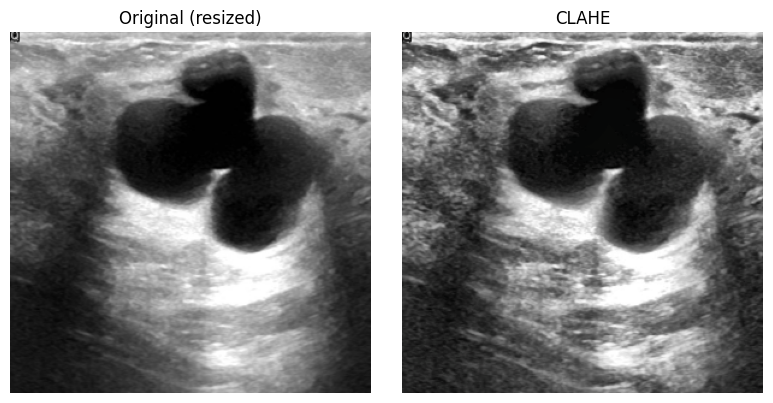

Class probabilities:
  [0] Benign    : 0.9832 <-- predicted
  [1] Malignant : 0.0155
  [2] Normal    : 0.0014
Explained class: [0] Benign
Saved: /content/drive/MyDrive/Busi_Model/GradCAM_PP/benign (18)_pred_Benign_explain_Benign_gradcampp.png


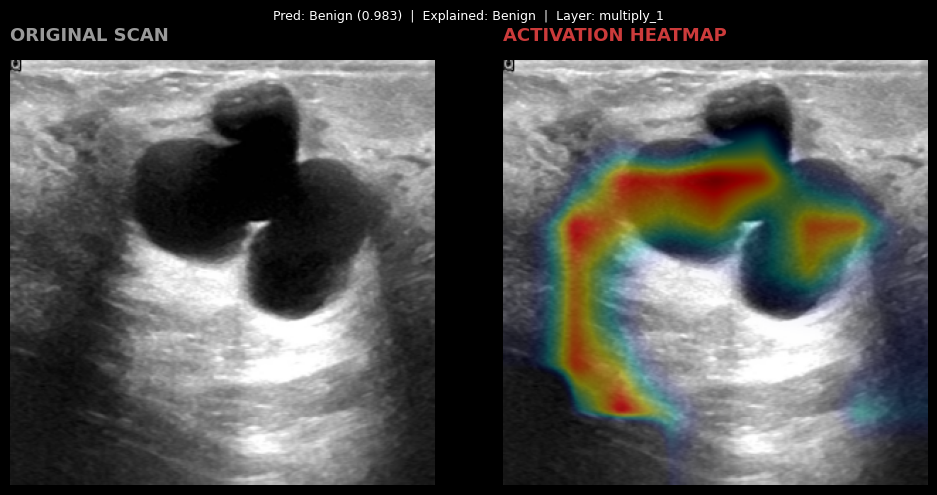

In [ ]:
from google.colab import files

uploaded = files.upload()

for fname in uploaded.keys():
    print("=" * 70)
    print("File:", fname)

    orig_uint8, clahe_uint8, model_input = load_and_preprocess(fname)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(orig_uint8); axes[0].set_title("Original (resized)"); axes[0].axis("off")
    axes[1].imshow(clahe_uint8); axes[1].set_title("CLAHE"); axes[1].axis("off")
    plt.tight_layout(); plt.show(); plt.close(fig)

    result = explain_image(
        fname, class_idx=class_index,
        save_name=os.path.splitext(fname)[0],
        show=True,
    )


## 14a. Prepare `TEST_DIR` from BUSI / BUS-UCLM Zips (optional)

Run this once to build a properly-structured `TEST_DIR` from your raw
dataset zips in Drive.

- **BUSI**: expects `benign/ malignant/ normal/`-style class subfolders
  (matched case-insensitively). Mask files are excluded.
- **BUS-UCLM**: expects a **flat `images/` folder plus an `INFO` Excel
  file** mapping each filename to its class — not class subfolders. The
  cell auto-detects the filename column and label column in the Excel
  sheet; if auto-detection picks the wrong columns, print the diagnostics
  it outputs and set `BUS_UCLM_FILENAME_COLUMN` / `BUS_UCLM_LABEL_COLUMN`
  / `LABEL_ALIASES` manually below and re-run.
- `BUSBRA` is skipped entirely if present anywhere — it must not be used.
- Mask files (any filename containing `mask`) are always excluded, per the
  unmasked-images-only requirement.


In [ ]:
import zipfile
import shutil
import pandas as pd

# >>> EDIT: paths to your zip files in Drive (set to None to skip one)
BUSI_ZIP_PATH = "/content/drive/MyDrive/Busi_Model/BUSI.zip"          # >>> EDIT
BUS_UCLM_ZIP_PATH = "/content/drive/MyDrive/Busi_Model/BUS_UCLM.zip"  # >>> EDIT

UNZIP_SCRATCH_DIR = "/content/dataset_scratch"                # local Colab disk, not Drive
MERGED_TEST_DIR = "/content/drive/MyDrive/Busi_Model/TestSet_Merged"  # >>> EDIT if desired

os.makedirs(UNZIP_SCRATCH_DIR, exist_ok=True)
os.makedirs(MERGED_TEST_DIR, exist_ok=True)
for cls in CLASS_NAMES:
    os.makedirs(os.path.join(MERGED_TEST_DIR, cls), exist_ok=True)

EXCLUDE_DIR_MARKERS = ("busbra",)  # never use BUSBRA, even if present in a zip
IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

# Maps raw label strings/codes found in the BUS-UCLM Excel sheet to CLASS_NAMES.
# Auto-detection lowercases values before matching, so keys here should be
# lowercase. Add entries here if your sheet uses different wording/codes
# (e.g. "b"/"m"/"n", or numeric 0/1/2).
LABEL_ALIASES = {
    "benign": "Benign", "malignant": "Malignant", "normal": "Normal",
    "b": "Benign", "m": "Malignant", "n": "Normal",
}

# >>> EDIT (only if auto-detection picks the wrong columns -- see printed
#           diagnostics below): force the exact column names to use.
BUS_UCLM_FILENAME_COLUMN = None  # e.g. "Image_filename"
BUS_UCLM_LABEL_COLUMN = None     # e.g. "Class"


def unzip_dataset(zip_path, extract_subdir):
    if not zip_path or not os.path.exists(zip_path):
        print(f"Skipping (not found): {zip_path}")
        return None
    dest = os.path.join(UNZIP_SCRATCH_DIR, extract_subdir)
    if os.path.isdir(dest) and os.listdir(dest):
        print(f"Already unzipped at {dest}, skipping extraction.")
        return dest
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(dest)
    print(f"Unzipped {zip_path} -> {dest}")
    return dest


def _class_name_from_folder(folder_name):
    lower = folder_name.lower()
    for cls in CLASS_NAMES:
        if cls.lower() == lower:
            return cls
    return None


def find_class_folders(root_dir):
    """Recursively find folders whose name matches a CLASS_NAMES entry
    (case-insensitive), skipping anything under an excluded dataset dir."""
    matches = {}
    for dirpath, dirnames, filenames in os.walk(root_dir):
        if any(marker in dirpath.lower() for marker in EXCLUDE_DIR_MARKERS):
            continue
        cls = _class_name_from_folder(os.path.basename(dirpath))
        if cls:
            matches.setdefault(cls, []).append(dirpath)
    return matches


def copy_images(src_folders, dest_dir, dataset_label):
    n_copied, n_masks_skipped = 0, 0
    for src_folder in src_folders:
        for fn in os.listdir(src_folder):
            if not fn.lower().endswith(IMG_EXTS):
                continue
            if "mask" in fn.lower():
                n_masks_skipped += 1
                continue
            shutil.copy2(os.path.join(src_folder, fn),
                         os.path.join(dest_dir, f"{dataset_label}_{fn}"))
            n_copied += 1
    return n_copied, n_masks_skipped


def process_busi(zip_path):
    print("=" * 70)
    print("Processing BUSI ...")
    extracted_root = unzip_dataset(zip_path, "busi")
    if extracted_root is None:
        return
    class_folders = find_class_folders(extracted_root)
    if not class_folders:
        print(f"  No class folders matching {CLASS_NAMES} found under {extracted_root}.")
        print("  Top-level contents for inspection:", os.listdir(extracted_root))
        return
    for cls, folders in class_folders.items():
        n_copied, n_skipped = copy_images(folders, os.path.join(MERGED_TEST_DIR, cls), "BUSI")
        print(f"  [BUSI] {cls}: copied {n_copied} images "
              f"(skipped {n_skipped} mask files) from {len(folders)} folder(s)")


def _find_info_excel(root_dir):
    candidates = []
    for dirpath, _, filenames in os.walk(root_dir):
        for fn in filenames:
            if fn.lower().endswith((".xlsx", ".xls")):
                candidates.append(os.path.join(dirpath, fn))
    # Prefer a file with "info" in the name if there's more than one
    info_named = [c for c in candidates if "info" in os.path.basename(c).lower()]
    return (info_named[0] if info_named else (candidates[0] if candidates else None))


def _find_images_dir(root_dir):
    best = None
    best_count = 0
    for dirpath, _, filenames in os.walk(root_dir):
        if any(marker in dirpath.lower() for marker in EXCLUDE_DIR_MARKERS):
            continue
        img_count = sum(1 for fn in filenames
                         if fn.lower().endswith(IMG_EXTS) and "mask" not in fn.lower())
        if img_count > best_count:
            best_count = img_count
            best = dirpath
    return best


def _auto_detect_columns(df, image_filenames):
    """Guess the filename column (values overlapping actual image filenames)
    and the label column (values overlapping LABEL_ALIASES keys)."""
    filename_col, label_col = None, None
    image_stems = {os.path.splitext(f)[0].lower() for f in image_filenames}

    best_overlap = 0
    for col in df.columns:
        vals = df[col].astype(str).str.strip().str.lower()
        overlap = sum(1 for v in vals if v in image_stems or
                      os.path.splitext(v)[0] in image_stems)
        if overlap > best_overlap:
            best_overlap = overlap
            filename_col = col

    best_overlap = 0
    for col in df.columns:
        if col == filename_col:
            continue
        vals = df[col].astype(str).str.strip().str.lower()
        overlap = sum(1 for v in vals if v in LABEL_ALIASES)
        if overlap > best_overlap:
            best_overlap = overlap
            label_col = col

    return filename_col, label_col


def process_bus_uclm(zip_path):
    print("=" * 70)
    print("Processing BUS-UCLM ...")
    extracted_root = unzip_dataset(zip_path, "bus_uclm")
    if extracted_root is None:
        return

    images_dir = _find_images_dir(extracted_root)
    info_path = _find_info_excel(extracted_root)

    if images_dir is None or info_path is None:
        print(f"  Could not locate both an images folder and an INFO Excel file "
              f"under {extracted_root}.")
        print("  Found images_dir:", images_dir)
        print("  Found info_path :", info_path)
        print("  Top-level contents:", os.listdir(extracted_root))
        return

    print(f"  Images folder: {images_dir}")
    print(f"  INFO file    : {info_path}")

    all_image_files = [f for f in os.listdir(images_dir)
                        if f.lower().endswith(IMG_EXTS) and "mask" not in f.lower()]

    df = pd.read_excel(info_path)

    fn_col = BUS_UCLM_FILENAME_COLUMN
    lbl_col = BUS_UCLM_LABEL_COLUMN
    if fn_col is None or lbl_col is None:
        auto_fn, auto_lbl = _auto_detect_columns(df, all_image_files)
        fn_col = fn_col or auto_fn
        lbl_col = lbl_col or auto_lbl

    print(f"  Using filename column: {fn_col!r}")
    print(f"  Using label column   : {lbl_col!r}")
    print(f"  Sheet columns available: {list(df.columns)}")
    print(f"  Sheet preview:\n{df.head(3)}")

    if fn_col is None or lbl_col is None:
        print("\n  Could not auto-detect the filename/label columns. Set "
              "BUS_UCLM_FILENAME_COLUMN and BUS_UCLM_LABEL_COLUMN above using "
              "the column names printed above, then re-run this cell.")
        return

    n_copied, n_skipped_mask, n_unmatched_label, n_missing_file = 0, 0, 0, 0
    for _, row in df.iterrows():
        raw_fn = str(row[fn_col]).strip()
        raw_label = str(row[lbl_col]).strip().lower()

        cls = LABEL_ALIASES.get(raw_label)
        if cls is None:
            n_unmatched_label += 1
            continue

        # Match raw_fn to an actual file in images_dir (allowing missing/extra extension)
        candidate = raw_fn if raw_fn.lower().endswith(IMG_EXTS) else None
        if candidate is None or not os.path.exists(os.path.join(images_dir, candidate)):
            stem = os.path.splitext(raw_fn)[0].lower()
            match = next((f for f in all_image_files
                          if os.path.splitext(f)[0].lower() == stem), None)
            candidate = match

        if candidate is None:
            n_missing_file += 1
            continue
        if "mask" in candidate.lower():
            n_skipped_mask += 1
            continue

        shutil.copy2(os.path.join(images_dir, candidate),
                     os.path.join(MERGED_TEST_DIR, cls, f"BUS_UCLM_{candidate}"))
        n_copied += 1

    print(f"\n  [BUS-UCLM] copied {n_copied} images | "
          f"unmatched labels: {n_unmatched_label} | "
          f"missing files: {n_missing_file} | mask rows skipped: {n_skipped_mask}")
    if n_unmatched_label > 0:
        print("  Some label values in the sheet didn't match LABEL_ALIASES. "
              "Add them (lowercase) to LABEL_ALIASES above and re-run if needed.")


process_busi(BUSI_ZIP_PATH)
process_bus_uclm(BUS_UCLM_ZIP_PATH)

print("\nMerged test set ready at:", MERGED_TEST_DIR)
for cls in CLASS_NAMES:
    cls_dir = os.path.join(MERGED_TEST_DIR, cls)
    count = len(os.listdir(cls_dir)) if os.path.isdir(cls_dir) else 0
    print(f"  {cls}: {count} images")

# Point TEST_DIR (from the Configuration cell) at the merged, properly-cased set:
TEST_DIR = MERGED_TEST_DIR
print("\nTEST_DIR set to:", TEST_DIR)


Processing BUSI ...
Skipping (not found): /content/drive/MyDrive/Busi_Model/BUSI.zip
Processing BUS-UCLM ...
Skipping (not found): /content/drive/MyDrive/Busi_Model/BUS_UCLM.zip

Merged test set ready at: /content/drive/MyDrive/Busi_Model/TestSet_Merged
  Benign: 437 images
  Malignant: 210 images
  Normal: 133 images

TEST_DIR set to: /content/drive/MyDrive/Busi_Model/TestSet_Merged


## 14. Dataset Testing (optional)

Visualizes images from `TEST_DIR`. Supports two layouts:

- **Labeled**: `TEST_DIR/<ClassName>/*.png` — true label is read from the
  subfolder name and compared against the prediction.
- **Flat/unlabeled**: `TEST_DIR/*.png` — no true label is shown.

Images are read from disk one at a time (never the whole dataset loaded
into RAM). Set `N_SAMPLES` / `SELECTED_FILES` below to control which images
are shown.


In [ ]:
IMG_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
MASK_MARKERS = ("mask",)  # BUSI/BUS-UCLM ship "<name>_mask.png" alongside each image

def _is_mask_file(filename):
    lower = filename.lower()
    return any(marker in lower for marker in MASK_MARKERS)

def _class_name_from_folder(folder_name):
    """Case-insensitive match of a folder name to CLASS_NAMES, e.g. 'benign' -> 'Benign'."""
    lower = folder_name.lower()
    for cls in CLASS_NAMES:
        if cls.lower() == lower:
            return cls
    return None

def _is_labeled_layout(test_dir):
    if not os.path.isdir(test_dir):
        return False
    subdirs = [d for d in os.listdir(test_dir) if os.path.isdir(os.path.join(test_dir, d))]
    return any(_class_name_from_folder(d) is not None for d in subdirs)

def list_test_images(test_dir, n_samples=6, seed=0, selected_files=None):
    """Returns list of (path, true_label_or_None). Case-insensitive class-folder
    matching; mask files (containing 'mask' in the filename) are excluded."""
    if selected_files:
        return [(p, None) for p in selected_files]

    if not os.path.isdir(test_dir):
        print(f"TEST_DIR not found or not set: {test_dir}. Skipping dataset testing.")
        return []

    pairs = []
    if _is_labeled_layout(test_dir):
        for entry in os.listdir(test_dir):
            entry_path = os.path.join(test_dir, entry)
            if not os.path.isdir(entry_path):
                continue
            cls = _class_name_from_folder(entry)
            if cls is None:
                continue
            for fn in os.listdir(entry_path):
                if fn.lower().endswith(IMG_EXTENSIONS) and not _is_mask_file(fn):
                    pairs.append((os.path.join(entry_path, fn), cls))
    else:
        for fn in os.listdir(test_dir):
            if fn.lower().endswith(IMG_EXTENSIONS) and not _is_mask_file(fn):
                pairs.append((os.path.join(test_dir, fn), None))

    random.Random(seed).shuffle(pairs)
    return pairs[:n_samples]


## 15. Malignant-Focused Visualization (optional)

Visualizes several **Malignant** test images specifically, showing all three
class probabilities and the Grad-CAM++ overlay for each. Predictions are
taken directly from the model with no manipulation of outputs or thresholds.


Found 6 malignant test image(s).
Image: /content/drive/MyDrive/Busi_Model/TestSet_Merged/Malignant/BUSI_malignant (182).png | True label: Malignant
  Benign probability   : 0.1008
  Malignant probability: 0.8823
  Normal probability   : 0.0169
  Predicted class      : Malignant
Saved: /content/drive/MyDrive/Busi_Model/GradCAM_PP/BUSI_malignant (182)_pred_Malignant_explain_Malignant_gradcampp.png


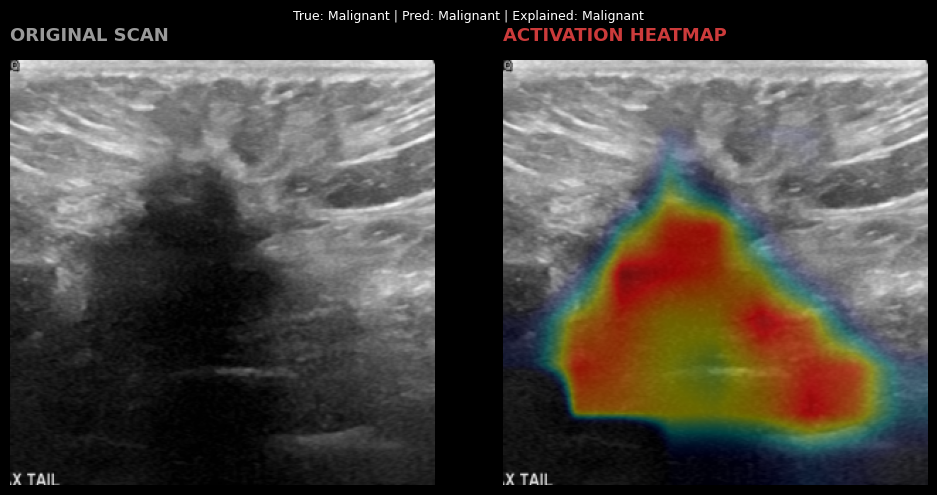

Image: /content/drive/MyDrive/Busi_Model/TestSet_Merged/Malignant/BUSI_malignant (18).png | True label: Malignant
  Benign probability   : 0.5760
  Malignant probability: 0.3038
  Normal probability   : 0.1202
  Predicted class      : Benign
Saved: /content/drive/MyDrive/Busi_Model/GradCAM_PP/BUSI_malignant (18)_pred_Benign_explain_Malignant_gradcampp.png


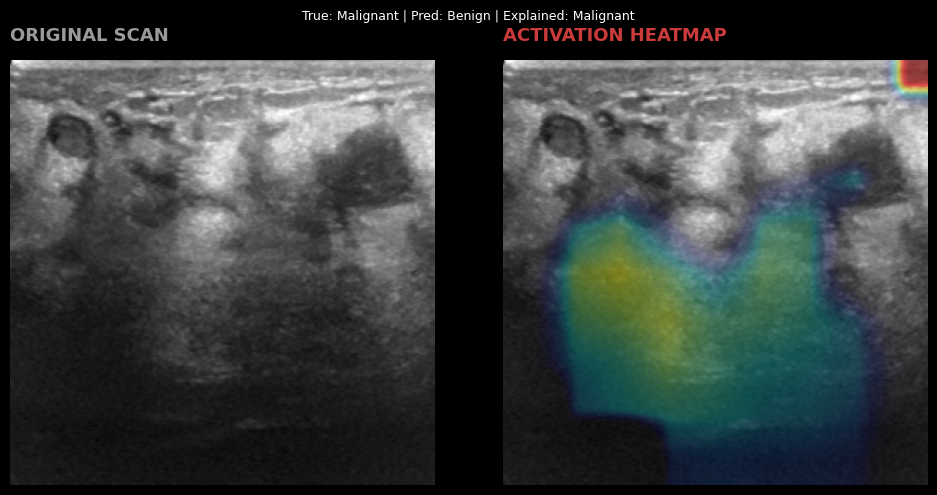

Image: /content/drive/MyDrive/Busi_Model/TestSet_Merged/Malignant/BUSI_malignant (86).png | True label: Malignant
  Benign probability   : 0.3881
  Malignant probability: 0.5674
  Normal probability   : 0.0446
  Predicted class      : Malignant
Saved: /content/drive/MyDrive/Busi_Model/GradCAM_PP/BUSI_malignant (86)_pred_Malignant_explain_Malignant_gradcampp.png


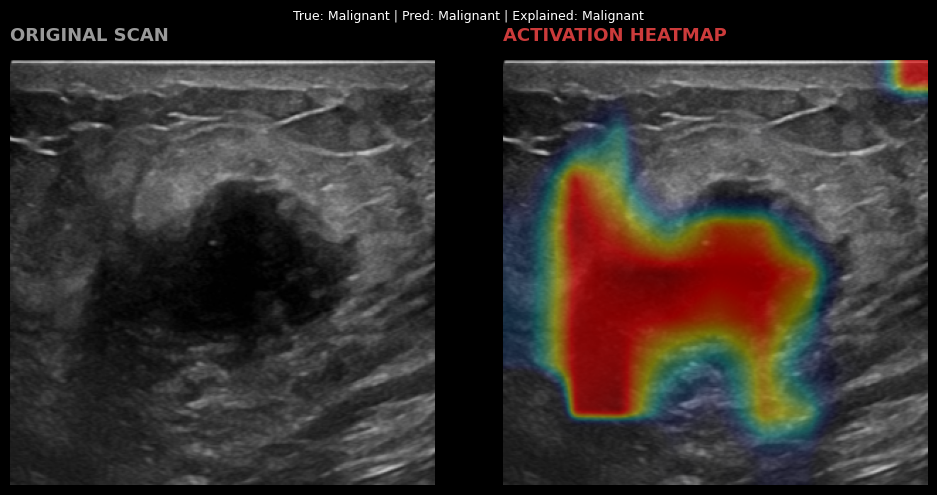

Image: /content/drive/MyDrive/Busi_Model/TestSet_Merged/Malignant/BUSI_malignant (130).png | True label: Malignant
  Benign probability   : 0.6182
  Malignant probability: 0.3809
  Normal probability   : 0.0009
  Predicted class      : Benign
Saved: /content/drive/MyDrive/Busi_Model/GradCAM_PP/BUSI_malignant (130)_pred_Benign_explain_Malignant_gradcampp.png


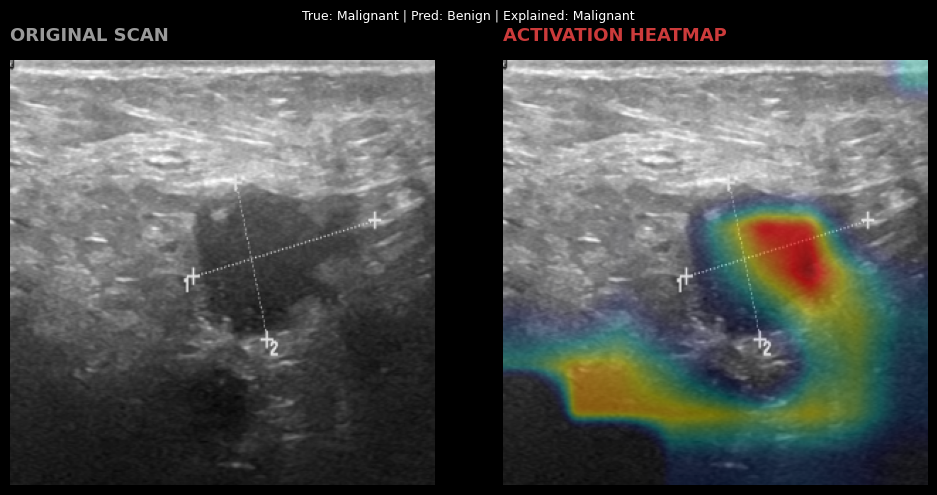

Image: /content/drive/MyDrive/Busi_Model/TestSet_Merged/Malignant/BUSI_malignant (190).png | True label: Malignant
  Benign probability   : 0.2987
  Malignant probability: 0.5659
  Normal probability   : 0.1354
  Predicted class      : Malignant
Saved: /content/drive/MyDrive/Busi_Model/GradCAM_PP/BUSI_malignant (190)_pred_Malignant_explain_Malignant_gradcampp.png


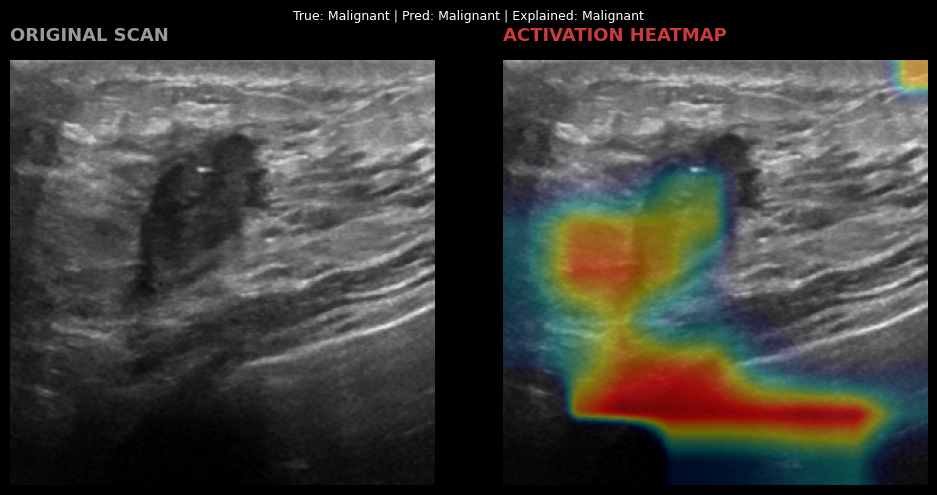

Image: /content/drive/MyDrive/Busi_Model/TestSet_Merged/Malignant/BUSI_malignant (196).png | True label: Malignant
  Benign probability   : 0.3311
  Malignant probability: 0.6515
  Normal probability   : 0.0175
  Predicted class      : Malignant
Saved: /content/drive/MyDrive/Busi_Model/GradCAM_PP/BUSI_malignant (196)_pred_Malignant_explain_Malignant_gradcampp.png


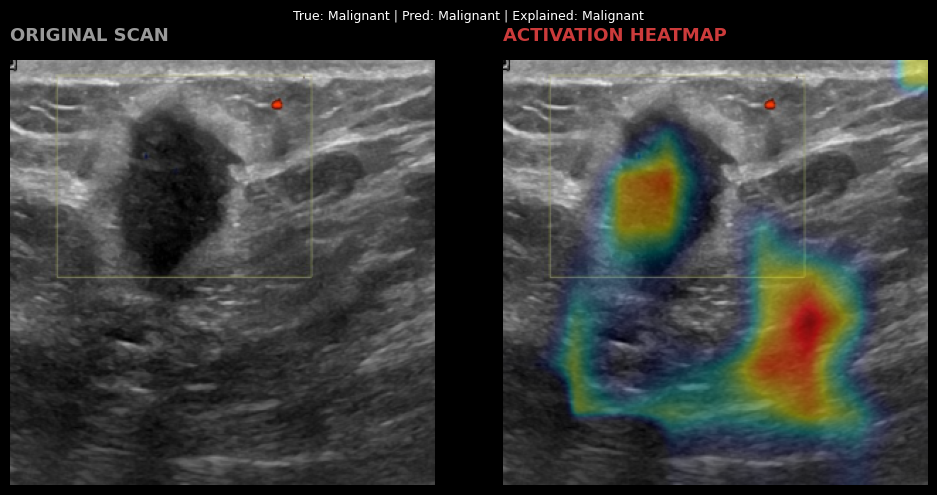

In [ ]:
N_MALIGNANT_SAMPLES = 6  # >>> EDIT if desired

def list_malignant_images(test_dir, n_samples=6, seed=0):
    if not _is_labeled_layout(test_dir):
        print("TEST_DIR is not in labeled <ClassName>/ layout; cannot isolate "
              "Malignant images automatically. Skipping.")
        return []
    malignant_dir = None
    for entry in os.listdir(test_dir):
        entry_path = os.path.join(test_dir, entry)
        if os.path.isdir(entry_path) and _class_name_from_folder(entry) == "Malignant":
            malignant_dir = entry_path
            break
    if malignant_dir is None:
        print(f"No 'Malignant' subfolder found under {test_dir}. Skipping.")
        return []
    files_ = [os.path.join(malignant_dir, f) for f in os.listdir(malignant_dir)
              if f.lower().endswith(IMG_EXTENSIONS) and not _is_mask_file(f)]
    random.Random(seed).shuffle(files_)
    return files_[:n_samples]

malignant_samples = list_malignant_images(TEST_DIR, n_samples=N_MALIGNANT_SAMPLES)
print(f"Found {len(malignant_samples)} malignant test image(s).")

for path in malignant_samples:
    print("=" * 70)
    print("Image:", path, "| True label: Malignant")

    orig_uint8, clahe_uint8, model_input = load_and_preprocess(path)
    probs, pred_idx = predict_single(model_input)

    print(f"  Benign probability   : {probs[0]:.4f}")
    print(f"  Malignant probability: {probs[1]:.4f}")
    print(f"  Normal probability   : {probs[2]:.4f}")
    print(f"  Predicted class      : {CLASS_NAMES[pred_idx]}")

    heatmap = gradcam_plusplus(model_input, class_idx=1)  # explain Malignant (idx 1)
    overlay = overlay_heatmap(orig_uint8, heatmap)

    save_path = os.path.join(
        OUTPUT_DIR,
        f"{os.path.splitext(os.path.basename(path))[0]}_pred_{CLASS_NAMES[pred_idx]}"
        f"_explain_Malignant_gradcampp.png"
    )
    show_gradcam(
        orig_uint8, heatmap, overlay,
        title=f"True: Malignant | Pred: {CLASS_NAMES[pred_idx]} | Explained: Malignant",
        save_path=save_path,
    )


## Sanity Checks

In [ ]:
print("Running sanity checks...")

# 1. 3 output classes
assert model.output_shape[-1] == 3, "Model must have exactly 3 output classes."
print("[OK] 3 output classes")

# 2. Class ordering
assert CLASS_NAMES == ["Benign", "Malignant", "Normal"], "Class ordering must be 0=Benign,1=Malignant,2=Normal."
print("[OK] Class ordering 0=Benign, 1=Malignant, 2=Normal")

# 3. Input shape 300x300x3
inp_shape = model.input_shape
if isinstance(inp_shape, list):
    inp_shape = inp_shape[0]
assert tuple(inp_shape[1:]) == (IMG_SIZE, IMG_SIZE, 3), f"Expected input (.,{IMG_SIZE},{IMG_SIZE},3), got {inp_shape}"
print(f"[OK] Input shape {IMG_SIZE}x{IMG_SIZE}x3")

# 4. Target layer is 4-D
tgt_layer = model.get_layer(TARGET_LAYER_NAME)
tgt_shape = _output_shape(tgt_layer)
assert tgt_shape is not None and len(tgt_shape) == 4, "Target layer output must be 4-D."
print(f"[OK] Target layer '{TARGET_LAYER_NAME}' is 4-D: {tgt_shape}")

# 5 & 6. Heatmap is 300x300 and values in [0, 1] -- run on a dummy input
_dummy = np.random.uniform(0, 255, size=(1, IMG_SIZE, IMG_SIZE, 3)).astype(np.float32)
_dummy_heatmap = gradcam_plusplus(_dummy, class_idx=0)
assert _dummy_heatmap.shape == (IMG_SIZE, IMG_SIZE), f"Heatmap shape mismatch: {_dummy_heatmap.shape}"
print(f"[OK] Heatmap shape {_dummy_heatmap.shape}")
assert _dummy_heatmap.min() >= 0.0 and _dummy_heatmap.max() <= 1.0, "Heatmap values must be in [0, 1]."
print(f"[OK] Heatmap values in [0, 1] (min={_dummy_heatmap.min():.3f}, max={_dummy_heatmap.max():.3f})")

print("\nAll sanity checks passed.")


Running sanity checks...
[OK] 3 output classes
[OK] Class ordering 0=Benign, 1=Malignant, 2=Normal
[OK] Input shape 300x300x3
[OK] Target layer 'multiply_1' is 4-D: (None, 9, 9, 2560)
[OK] Heatmap shape (300, 300)
[OK] Heatmap values in [0, 1] (min=0.000, max=0.000)

All sanity checks passed.


## 16. Save Visualizations to Drive

All `explain_image(...)` calls above with a `save_name` (Section 13) and all
dataset/malignant-focused visualizations (Sections 14–15) already save their
triptych figures to `OUTPUT_DIR` as they run, using the naming convention:

```text
image123_pred_Malignant_explain_Malignant_gradcampp.png
```

This cell just confirms what has been written so far.


In [ ]:
saved_files = sorted(glob.glob(os.path.join(OUTPUT_DIR, "*_gradcampp.png")))
print(f"{len(saved_files)} Grad-CAM++ visualization(s) saved in {OUTPUT_DIR}:")
for f in saved_files:
    print(" -", os.path.basename(f))


25 Grad-CAM++ visualization(s) saved in /content/drive/MyDrive/Busi_Model/GradCAM_PP:
 - BUSI_malignant (130)_pred_Benign_explain_Malignant_gradcampp.png
 - BUSI_malignant (18)_pred_Benign_explain_Malignant_gradcampp.png
 - BUSI_malignant (182)_pred_Malignant_explain_Malignant_gradcampp.png
 - BUSI_malignant (190)_pred_Malignant_explain_Malignant_gradcampp.png
 - BUSI_malignant (196)_pred_Malignant_explain_Malignant_gradcampp.png
 - BUSI_malignant (86)_pred_Malignant_explain_Malignant_gradcampp.png
 - benign (10)_pred_Benign_explain_Benign_gradcampp.png
 - benign (121) (1)_pred_Benign_explain_Benign_gradcampp.png
 - benign (121)_pred_Benign_explain_Benign_gradcampp.png
 - benign (13) (1)_pred_Benign_explain_Benign_gradcampp.png
 - benign (13) (2)_pred_Benign_explain_Benign_gradcampp.png
 - benign (13) (3)_pred_Benign_explain_Benign_gradcampp.png
 - benign (13)_pred_Benign_explain_Benign_gradcampp.png
 - benign (145)_pred_Benign_explain_Benign_gradcampp.png
 - benign (17)_pred_Benign_ex